# Final Project – Part 1: Exploratory Data Analysis
### Second-hand fashion marketplace

## Introduction

This notebook is the first part of a final data analytics project. The scenario: I work for a **second-hand clothing marketplace**, a platform that lets people resell their used clothes, accessories and shoes, giving garments a second life and offering an ethical alternative to fast fashion.

The dataset contains **999 sales** made by users on the platform between January 2021 and December 2023. Each row is one transaction, with information about the seller (ID, country, language, subscription date), the item (category, designer, price level, average star rating) and the payment platform.

**Goal of the analysis:** explore the data to gain insight into user behaviour, and in particular to understand:
- which products and designers have been most successful;
- how sales trend over time across the year;
- which groups of users exist, as a basis for the user personas;
- what contributes most to a product's success, to inform next year's strategy.

**Structure of the notebook:**
1. Setup, data loading and quality checks
2. Date cleaning and feature engineering
3. Univariate analysis of categorical variables
4. Time trends
5. Cross analysis: what drives product success
6. User-level analysis
7. Key insights and conclusions
8. Export of the user-level table for the Tableau dashboard (part 2)

| Column | Description |
|---|---|
| `purchase_date` | Date on which the user sold the item |
| `user_uuid` | ID of the selling user |
| `category` | Clothing category |
| `designer_id` | Designer ID |
| `language` | Language of the selling user |
| `level` | Price level |
| `country` | Country of the selling user |
| `subscription_date` | Date on which the selling user signed up |
| `platform` | Platform used for the payment |
| `item_id` | Item ID |
| `stars` | Average stars given to the item (1 to 5) |

## Libraries

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## Setup and data loading

In [2]:
# Display settings
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
%matplotlib inline

# Load the dataset
df = pd.read_csv('Fashion_data_Final_Project.csv')

df.shape

(999, 11)

## General overview and quality checks

In [3]:
# First rows of the dataset
df.head()

,user_uuid,category,designer_id,language,level,country,purchase_date,platform,item_id,stars,subscription_date
0,183,belt,120,en,cheap,uk,13-7-2022,android,3521,1,20-8-2021
1,134,underwear,102,it,cheap,it,2-5-2023,android,6239,2,20-11-2022
2,158,belt,106,it,cheap,it,6-8-2021,pc,3618,3,18-3-2020
3,82,shoes,102,it,premium,it,18-7-2023,android,5281,4,21-1-2022
4,201,shoes,113,en,average,uk,7-5-2023,android,5260,1,25-11-2022


In [4]:
# General info: data types and non-null values per column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 999 entries, 0 to 998
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   user_uuid          999 non-null    int64 
 1   category           999 non-null    object
 2   designer_id        999 non-null    int64 
 3   language           999 non-null    object
 4   level              999 non-null    object
 5   country            999 non-null    object
 6   purchase_date      999 non-null    object
 7   platform           999 non-null    object
 8   item_id            999 non-null    int64 
 9   stars              999 non-null    int64 
 10  subscription_date  999 non-null    object
dtypes: int64(4), object(7)
memory usage: 86.0+ KB


In [5]:
# Missing values per column
df.isna().sum()

user_uuid            0
category             0
designer_id          0
language             0
level                0
country              0
purchase_date        0
platform             0
item_id              0
stars                0
subscription_date    0
dtype: int64

In [6]:
# Duplicate rows (identical across all columns)
df.duplicated().sum()

np.int64(0)

There are no missing values and no duplicate rows.

In [7]:
# Descriptive statistics for the numeric columns
df.describe()

,user_uuid,designer_id,item_id,stars
count,999.000000,999.000000,999.000000,999.000000
mean,126.206206,110.769770,4032.721722,3.013013
std,68.581911,6.623049,2266.843497,1.415216
min,1.000000,100.000000,26.000000,1.000000
25%,69.000000,105.000000,2248.000000,2.000000
50%,128.000000,111.000000,3662.000000,3.000000
75%,183.500000,116.000000,5972.500000,4.000000
max,245.000000,122.000000,11000.000000,5.000000


In [8]:
# Unique values for each categorical column
for col in ['category', 'language', 'level', 'country', 'platform']:
    print(f"{col}: {df[col].nunique()} unique values -> {sorted(df[col].unique())}")

category: 7 unique values -> ['activewear', 'belt', 'bottom', 'dress', 'shirt', 'shoes', 'underwear']
language: 3 unique values -> ['en', 'fr', 'it']
level: 3 unique values -> ['average', 'cheap', 'premium']
country: 3 unique values -> ['fr', 'it', 'uk']
platform: 3 unique values -> ['android', 'apple', 'pc']


In [9]:
# Number of unique users, designers and items
print("Unique users:", df['user_uuid'].nunique())
print("Unique designers:", df['designer_id'].nunique())
print("Unique items:", df['item_id'].nunique(), "out of", len(df), "total rows")

Unique users: 241
Unique designers: 23
Unique items: 901 out of 999 total rows


The dataset contains 999 sales but only 901 unique `item_id` values (98 duplicates). These duplicates are examined more closely below.

In [10]:
# Isolate the rows that share the same item_id
duplicated_items = df[df.duplicated(subset='item_id', keep=False)].sort_values('item_id')

# For each duplicated item_id, count how many different categories/designers/users appear
check_duplicates = duplicated_items.groupby('item_id').agg(
    n_categories=('category', 'nunique'),
    n_designers=('designer_id', 'nunique'),
    n_users=('user_uuid', 'nunique'),
    n_occurrences=('item_id', 'count')
)

check_duplicates.head(10)

,n_categories,n_designers,n_users,n_occurrences
item_id,,,,
33,1,2,2,2
310,1,2,2,2
320,1,2,2,2
322,1,2,2,2
335,1,2,2,2
336,1,2,2,2
360,1,2,2,2
389,1,2,2,2
393,1,2,2,2


In [11]:
# A concrete example: one duplicated item_id in detail
example_id = check_duplicates.index[0]
df[df['item_id'] == example_id]

,user_uuid,category,designer_id,language,level,country,purchase_date,platform,item_id,stars,subscription_date
299,243,belt,100,en,cheap,uk,19-9-2021,apple,33,1,24-8-2020
404,33,belt,119,fr,cheap,fr,20-3-2023,android,33,5,2-7-2022


In [12]:
# How many duplicated item_ids actually have a different category AND/OR designer?
different = check_duplicates[(check_duplicates['n_categories'] > 1) | (check_duplicates['n_designers'] > 1)]
print(f"Duplicated item_ids with a different category or designer: {len(different)} out of {len(check_duplicates)}")

Duplicated item_ids with a different category or designer: 90 out of 91


Looking at these duplicates, rows with the same `item_id` often have a different category and/or designer: this means they are not the same item resold several times, but most likely a collision in the generation of product IDs. As a result, **`item_id` cannot be used as a unique key** to count distinct items. For product-level analyses, a combination of columns will be used (e.g. category + designer), or the analysis will be carried out directly at row/sale level.

## Date cleaning and feature engineering
In this section:
- Dates are converted using the format `'%d-%m-%Y'` (specifying it explicitly avoids ambiguity and is faster than pandas' automatic parsing).
- A consistency check verifies that no sale took place before the user signed up.
- `purchase_year`, `purchase_month` and `purchase_weekday` will be used later to analyse time trends (e.g. sales per month, seasonality, most active day of the week).
- `purchase_year_month` (Period type) makes it easy to aggregate by month or year while keeping the chronological order in charts.
- `account_tenure_days` / `account_tenure_months` measure how long a user has been registered at the time of a sale: useful to understand whether more loyal users sell more, or sell higher-value items.

In [13]:
# Convert the date columns (dd-mm-yyyy format)
df['purchase_date'] = pd.to_datetime(df['purchase_date'], format='%d-%m-%Y')
df['subscription_date'] = pd.to_datetime(df['subscription_date'], format='%d-%m-%Y')

df[['purchase_date', 'subscription_date']].dtypes

purchase_date        datetime64[ns]
subscription_date    datetime64[ns]
dtype: object

In [14]:
# Consistency check: no sale should happen before the subscription date
inconsistent_rows = df[df['purchase_date'] < df['subscription_date']]
print(f"Rows with a sale before the subscription date: {len(inconsistent_rows)}")

Rows with a sale before the subscription date: 0


In [15]:
# Time features related to the sale
df['purchase_year'] = df['purchase_date'].dt.year
df['purchase_month'] = df['purchase_date'].dt.month
df['purchase_weekday'] = df['purchase_date'].dt.day_name()
df['purchase_year_month'] = df['purchase_date'].dt.to_period('M')

In [16]:
# Account tenure at the time of the sale (in days and in months)
df['account_tenure_days'] = (df['purchase_date'] - df['subscription_date']).dt.days
df['account_tenure_months'] = (df['account_tenure_days'] / 30.44).round(1)

df[['subscription_date', 'purchase_date', 'account_tenure_days', 'account_tenure_months']].head()

,subscription_date,purchase_date,account_tenure_days,account_tenure_months
0,2021-08-20,2022-07-13,327,10.7
1,2022-11-20,2023-05-02,163,5.4
2,2020-03-18,2021-08-06,506,16.6
3,2022-01-21,2023-07-18,543,17.8
4,2022-11-25,2023-05-07,163,5.4


In [17]:
# Quick statistics on account tenure
df['account_tenure_days'].describe()

count     999.000000
mean      558.029029
std       287.826205
min        10.000000
25%       346.000000
50%       509.000000
75%       751.000000
max      1395.000000
Name: account_tenure_days, dtype: float64

## Univariate analysis of categorical variables
This section looks at the distribution of each categorical variable to understand the overall composition of the dataset: which product categories, price levels, countries, languages and platforms are most represented.

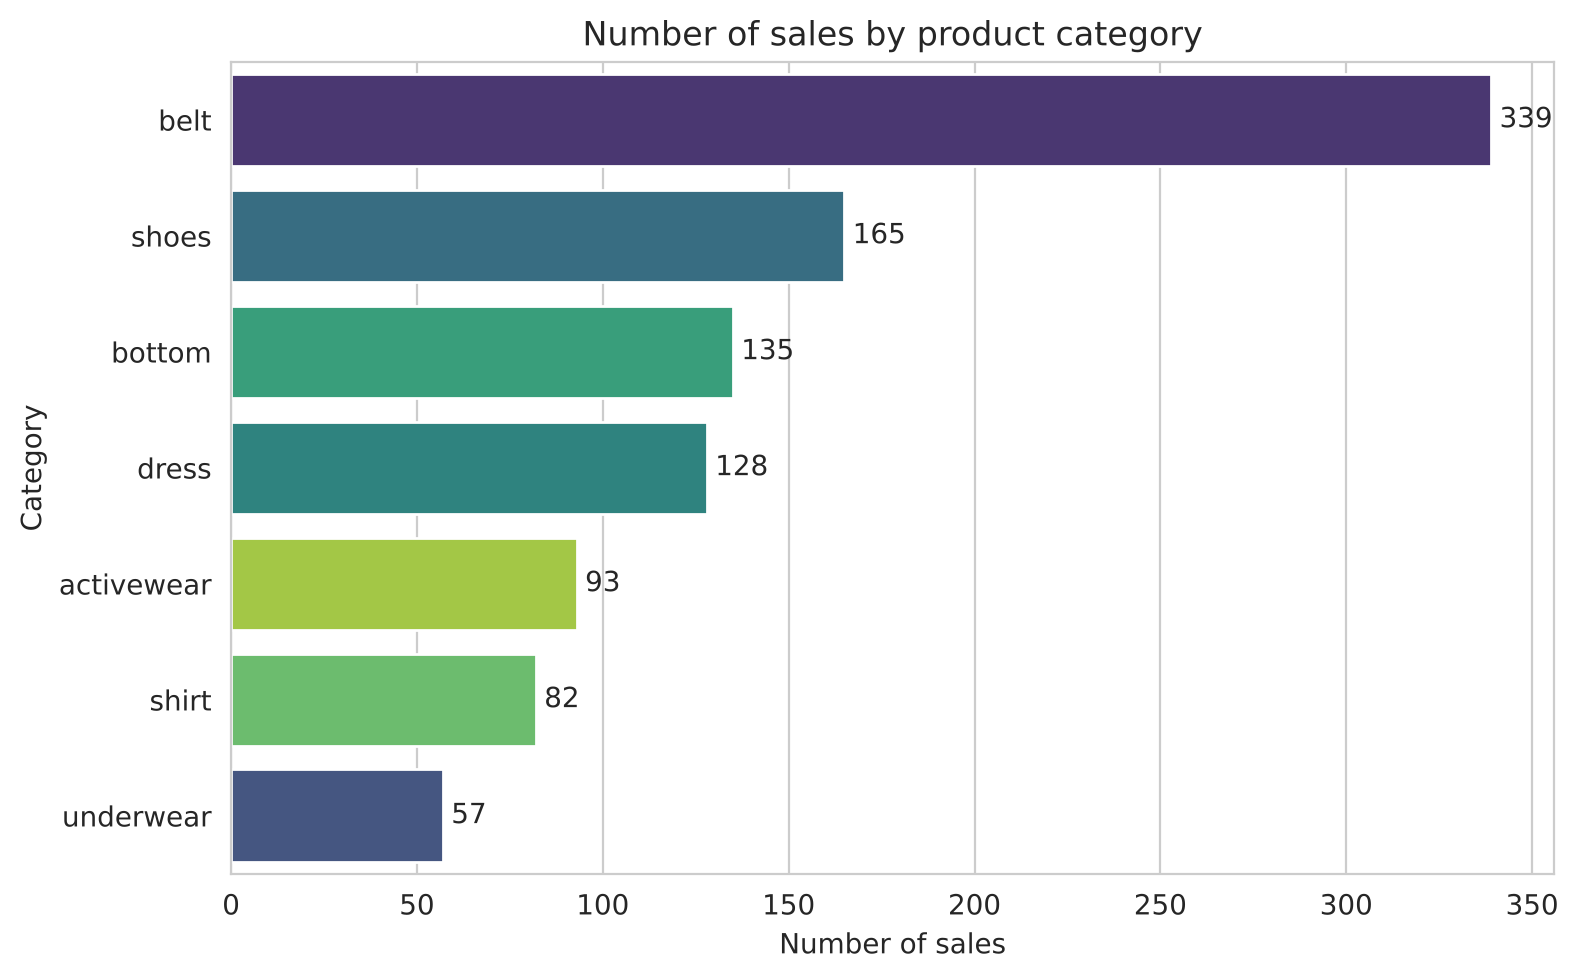

In [18]:
# Sales distribution by product category
plt.figure(figsize=(8, 5))
order = df['category'].value_counts().index
ax = sns.countplot(data=df, y='category', order=order, hue='category', palette='viridis', legend=False)

# Add the exact count at the end of each bar
for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('Number of sales by product category')
plt.xlabel('Number of sales')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

In [19]:
# Summary table: count and percentage per category
category_summary = df['category'].value_counts().to_frame(name='count')
category_summary['percentage'] = (category_summary['count'] / len(df) * 100).round(1)

category_summary

,count,percentage
category,,
belt,339,33.9
shoes,165,16.5
bottom,135,13.5
dress,128,12.8
activewear,93,9.3
shirt,82,8.2
underwear,57,5.7


The category countplot immediately shows which types of items are resold most often on the platform. This answers the question: *"which products have been most successful?"*

In a second-hand clothing marketplace one would expect garments such as shirts or shoes to dominate, not accessories like belts.

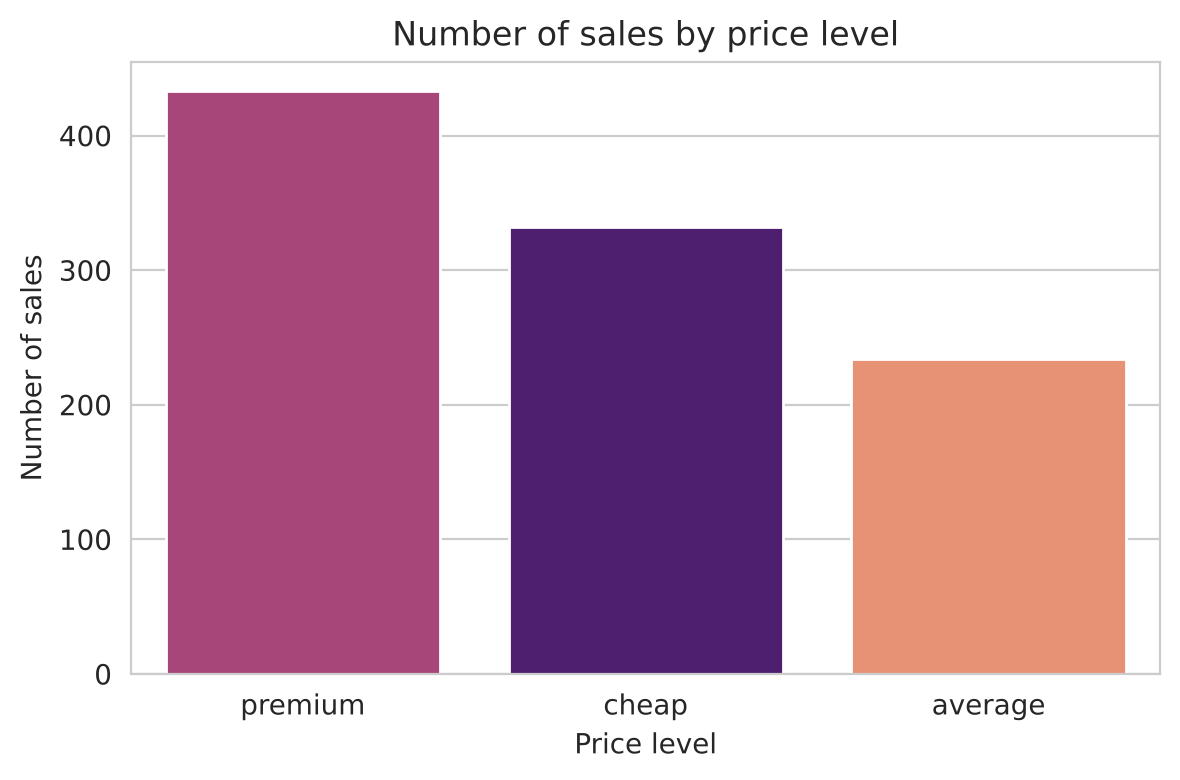

In [20]:
# Sales distribution by price level
plt.figure(figsize=(6, 4))
order = df['level'].value_counts().index
sns.countplot(data=df, x='level', order=order, hue='level', palette='magma', legend=False)
plt.title('Number of sales by price level')
plt.xlabel('Price level')
plt.ylabel('Number of sales')
plt.tight_layout()
plt.show()

The `level` chart shows the mix of cheap / average / premium items: useful to understand the overall positioning of the marketplace.

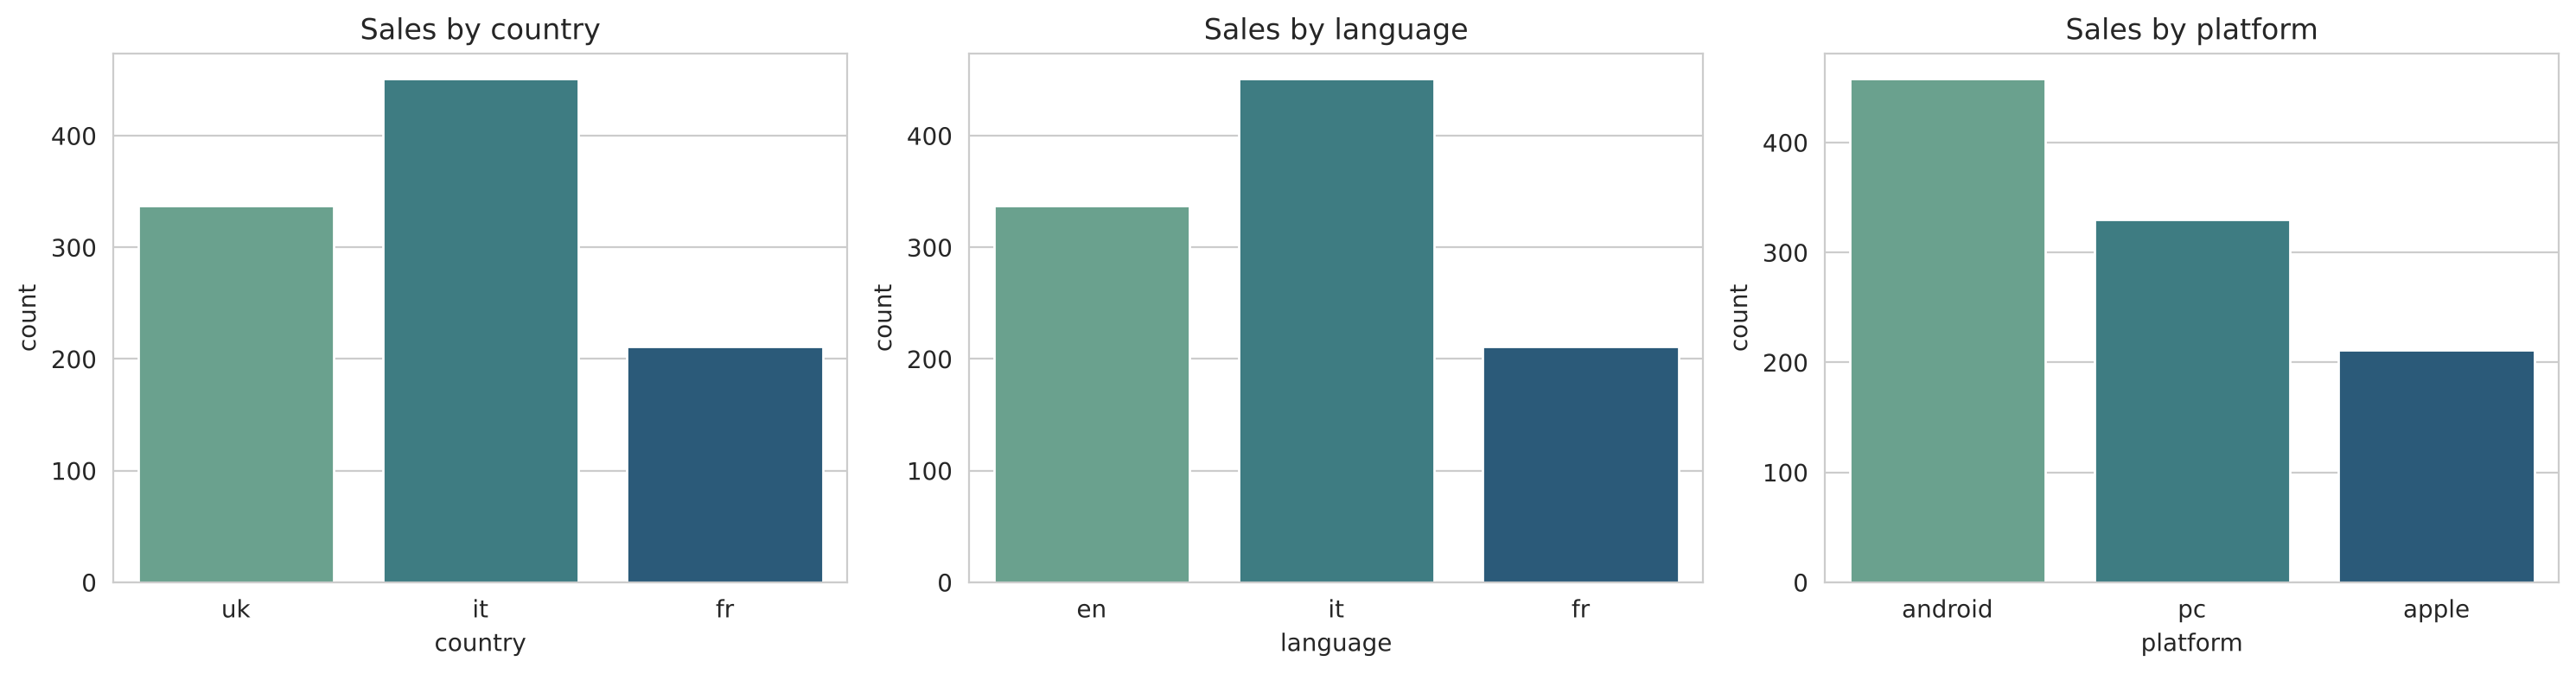

In [21]:
# Distribution by country, language and platform (single figure with subplots)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.countplot(data=df, x='country', hue='country', ax=axes[0], palette='crest', legend=False)
axes[0].set_title('Sales by country')

sns.countplot(data=df, x='language', hue='language', ax=axes[1], palette='crest', legend=False)
axes[1].set_title('Sales by language')

sns.countplot(data=df, x='platform', hue='platform', ax=axes[2], palette='crest', legend=False)
axes[2].set_title('Sales by platform')

plt.tight_layout()
plt.show()

The result shows a perfect one-to-one match between the first two plots: all UK users speak English, all IT users speak Italian, all FR users speak French, with zero exceptions. In this dataset `language` appears to be redundant with `country`: they are the same information encoded twice.
If they were two independent fields, one would expect a share of users selling in English without being native speakers.

The third plot is not surprising: purchases are mostly made from phones, and Android is the most widespread operating system.

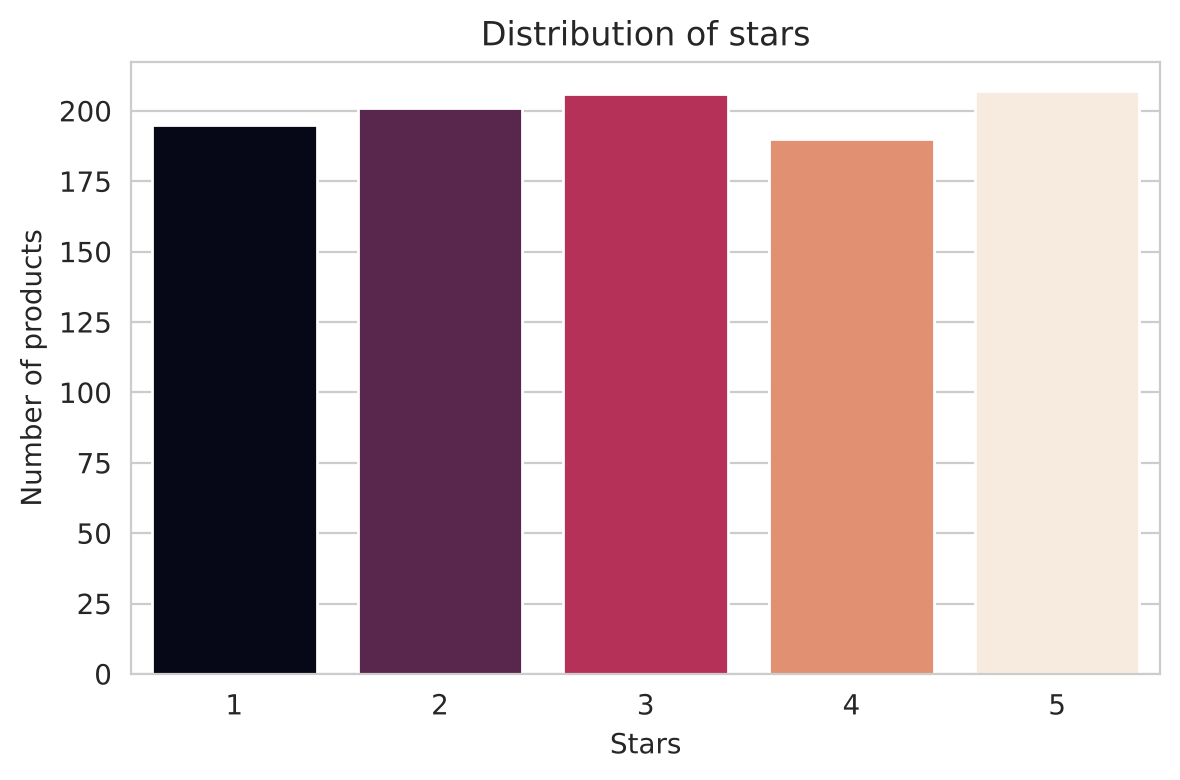

count    999.000000
mean       3.013013
std        1.415216
min        1.000000
25%        2.000000
50%        3.000000
75%        4.000000
max        5.000000
Name: stars, dtype: float64


In [22]:
# Distribution of the stars given to products
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='stars', hue='stars', palette='rocket', legend=False)
plt.title('Distribution of stars')
plt.xlabel('Stars')
plt.ylabel('Number of products')
plt.tight_layout()
plt.show()

print(df['stars'].describe())

The distribution of `stars` matters: if it were strongly skewed towards high or low values, it would say something about overall perceived quality. It will also be used later to understand what contributes to a product's success.

The distribution is almost perfectly uniform (each value close to 20%). Real online reviews usually follow a "J-shaped" distribution, or are at least skewed upwards, because satisfied customers buy more and those who had a serious problem are a minority.

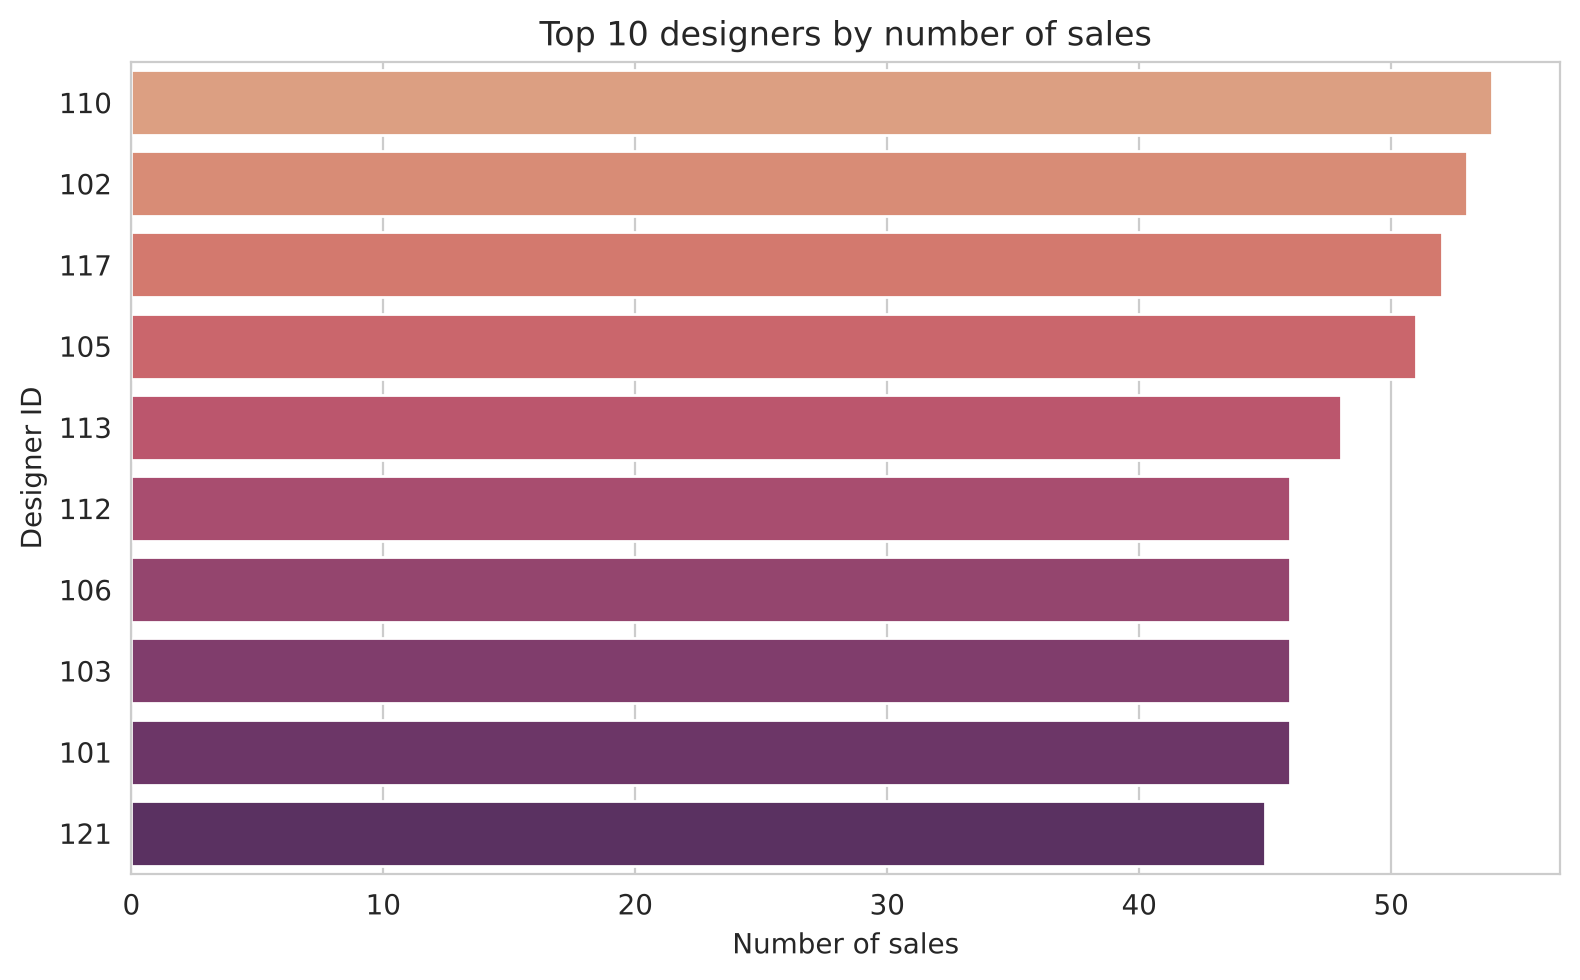

In [23]:
# Top 10 designers by number of sales
top_designers = df['designer_id'].value_counts().head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=top_designers.values, y=top_designers.index.astype(str), hue=top_designers.index.astype(str), palette='flare', legend=False)
plt.title('Top 10 designers by number of sales')
plt.xlabel('Number of sales')
plt.ylabel('Designer ID')
plt.tight_layout()
plt.show()

The top 10 designers chart directly answers another key question from the brief (*"which designers have been most successful?"*).
It can also be useful to:

- Find out whether some designers are driving sales, which can help decide whether to give them more visibility on the home page, or to negotiate dedicated partnerships/promotions.
- Lay the groundwork for a cross analysis later on. Successful designers will be crossed with `level` and `stars`: a designer may sell a lot but have low ratings (high volume, low perceived quality), or sell little but with excellent ratings (niche but appreciated). Always keeping in mind the question *"what contributes to a product's success?"*
- Establish whether the distribution is concentrated (a few designers account for most sales) or fairly even across all of them. This also helps decide whether it makes sense, later on, to build clusters/segments on the designer side and not only on the user side.

## Time trends
This section looks at how sales are distributed over time: monthly trend, year-over-year comparison, seasonality and most active day of the week.

In [24]:
# Time coverage check: are the first and last months complete?
print("First date:", df['purchase_date'].min())
print("Last date:", df['purchase_date'].max())

First date: 2021-01-01 00:00:00
Last date: 2023-12-28 00:00:00


The time coverage of the dataset is almost complete at both ends (1 Jan 2021 – 28 Dec 2023): the comparison between years is not distorted by partial months.

In [25]:
# Sales aggregated by year-month and by year
monthly_sales = df.groupby('purchase_year_month').size()
yearly_sales = df.groupby('purchase_year').size()

print(monthly_sales.head(3))
print(monthly_sales.tail(3))
print()
print(yearly_sales)
print()
print("Growth 2021 -> 2023:", round((yearly_sales[2023] / yearly_sales[2021] - 1) * 100, 1), "%")

purchase_year_month
2021-01    10
2021-02     7
2021-03     6
Freq: M, dtype: int64
purchase_year_month
2023-10    39
2023-11    55
2023-12    50
Freq: M, dtype: int64

purchase_year
2021     93
2022    308
2023    598
dtype: int64

Growth 2021 -> 2023: 543.0 %


The monthly distribution shows strong growth in sales volume from 2021 to 2023 (the first months of 2021 record about 6–10 sales per month, against 39–55 sales per month at the end of 2023). Since the time coverage is almost complete at both ends (1 Jan 2021 – 28 Dec 2023), the comparison between years is not distorted by partial months: the observed growth reflects a real trend in the data, consistent with a marketplace in an expansion phase.

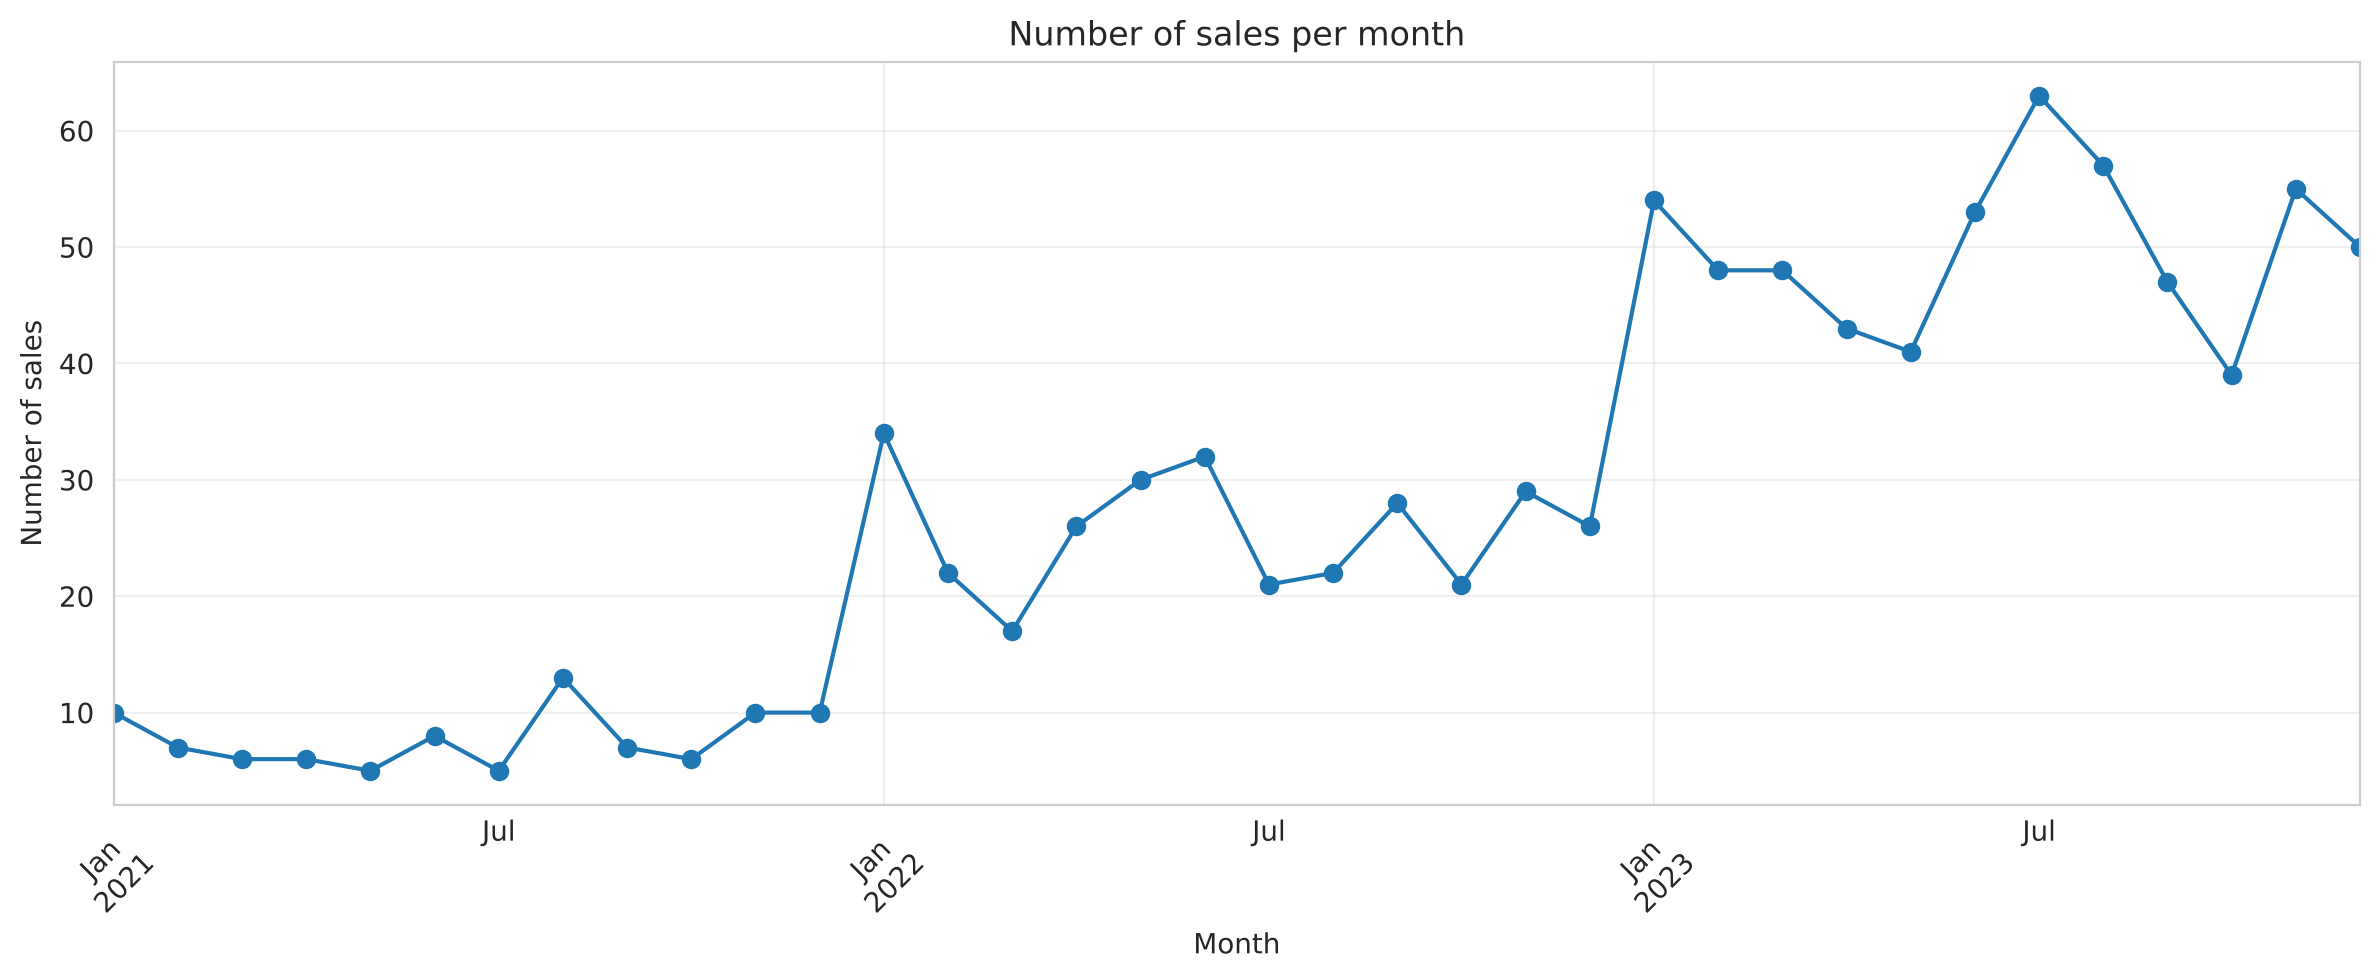

In [26]:
# Sales per year-month (continuous time series)
monthly_sales = df.groupby('purchase_year_month').size()

plt.figure(figsize=(12, 5))
monthly_sales.plot(kind='line', marker='o')
plt.title('Number of sales per month')
plt.xlabel('Month')
plt.ylabel('Number of sales')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

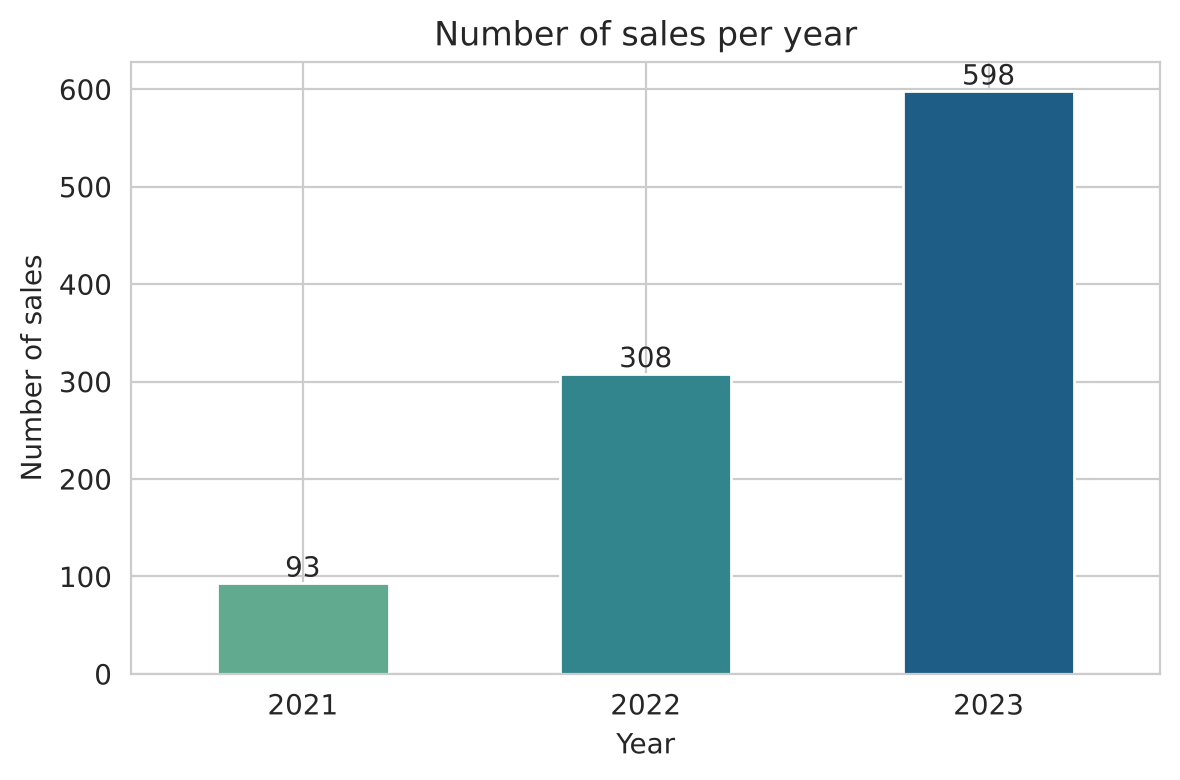

In [27]:
# Total sales per year
yearly_sales = df.groupby('purchase_year').size()

plt.figure(figsize=(6, 4))
ax = yearly_sales.plot(kind='bar', color=sns.color_palette('crest', len(yearly_sales)))
ax.bar_label(ax.containers[0])
plt.title('Number of sales per year')
plt.xlabel('Year')
plt.ylabel('Number of sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

As noted above, sales volume grew steadily from 2021 to 2023.

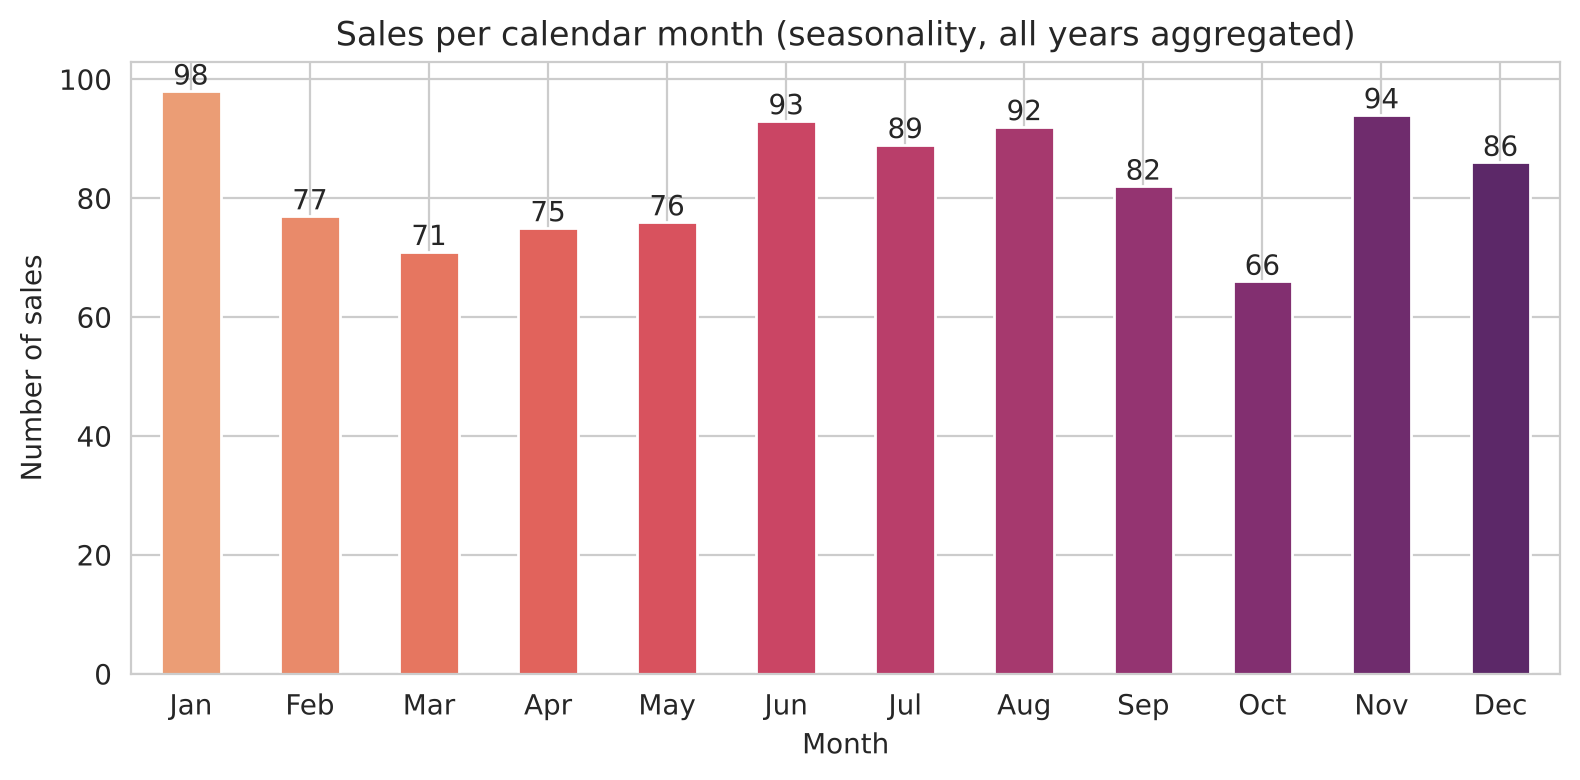

In [28]:
# Seasonality: sales per calendar month (all years aggregated)
seasonal = df.groupby('purchase_month').size()

plt.figure(figsize=(8, 4))
ax = seasonal.plot(kind='bar', color=sns.color_palette('flare', 12))
ax.bar_label(ax.containers[0])
plt.title('Sales per calendar month (seasonality, all years aggregated)')
plt.xlabel('Month')
plt.ylabel('Number of sales')
plt.xticks(ticks=range(12), labels=['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'], rotation=0)
plt.tight_layout()
plt.show()

The seasonality chart (calendar month, all years aggregated) differs from the first one: here, for example, all the Marches of 2021, 2022 and 2023 are added together, to see whether some months are typically stronger, for instance around changes of season or the Christmas holidays.

There is, for example, a peak in January, which could be due to people reselling unwanted Christmas presents (or presents in the wrong size).

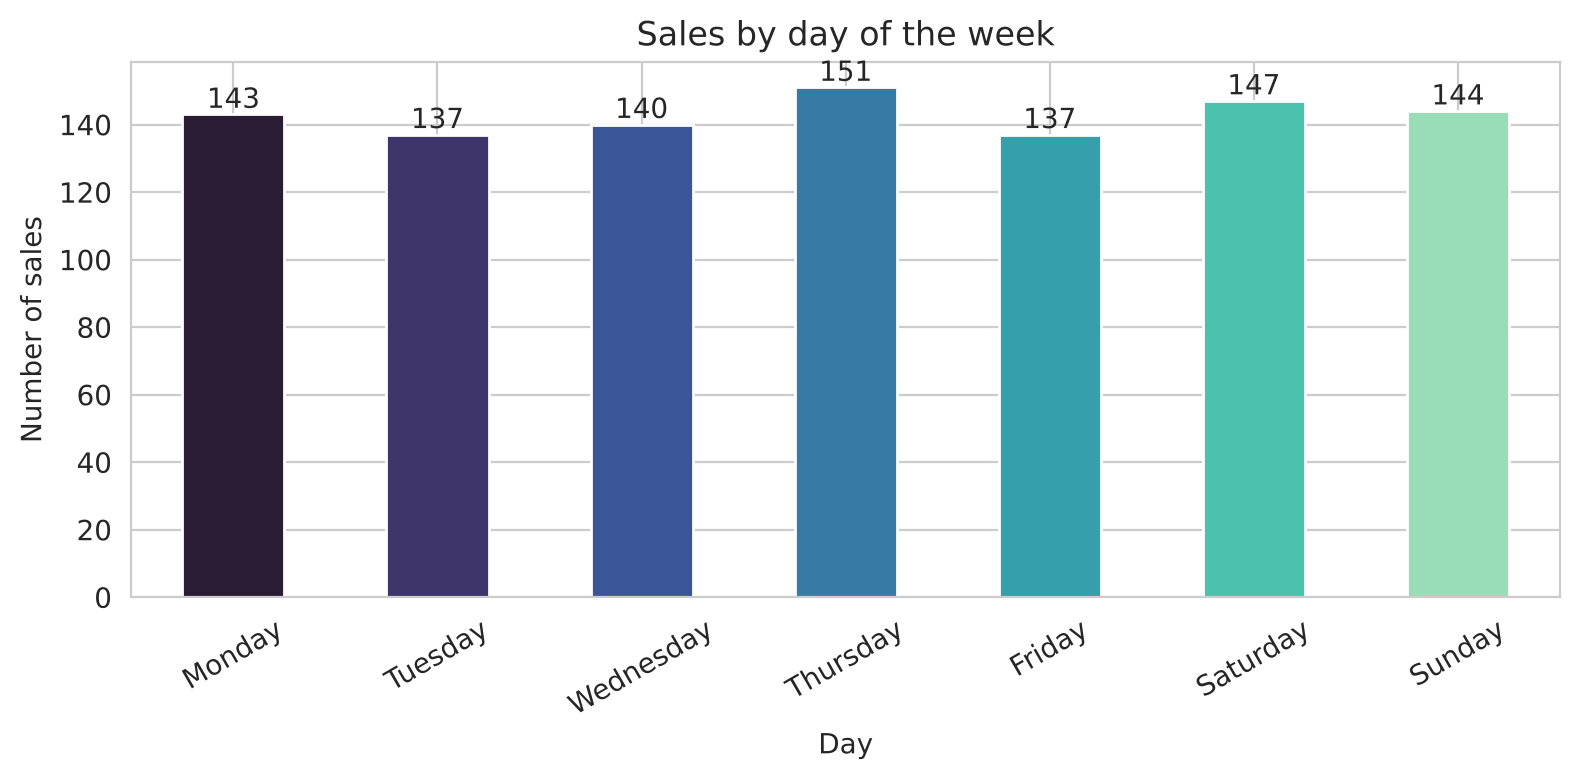

In [29]:
# Sales by day of the week
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_sales = df['purchase_weekday'].value_counts().reindex(weekday_order)

plt.figure(figsize=(8, 4))
ax = weekday_sales.plot(kind='bar', color=sns.color_palette('mako', 7))
ax.bar_label(ax.containers[0])
plt.title('Sales by day of the week')
plt.xlabel('Day')
plt.ylabel('Number of sales')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

The day of the week can reveal usage habits.

Here the distribution is fairly balanced, with a peak on Thursday and a low on Tuesday. Saturday comes second, perhaps because at the weekend users have more free time to photograph and list items. Still, no day clearly dominates.

## Cross analysis: what drives product success
Variables are now crossed to start answering the most strategic question: what makes a product / category / designer successful.
The analysis looks at category × stars, level × stars, and designer × stars/level.

In [30]:
# Average rating (stars) per product category
category_stars = df.groupby('category')['stars'].agg(['mean', 'count']).sort_values('mean', ascending=False)
category_stars['mean'] = category_stars['mean'].round(2)

category_stars

,mean,count
category,,
belt,3.10,339
shoes,3.07,165
underwear,3.05,57
bottom,2.99,135
dress,2.98,128
activewear,2.85,93
shirt,2.78,82


This shows whether the best-selling categories (e.g. belt) are also the best rated, or whether they sell a lot but with mediocre reviews.

Here the answer is yes, the best-selling categories have higher ratings, but only marginally. Unfortunately all ratings should be considered mediocre: an average of 3.10 is far from ideal.

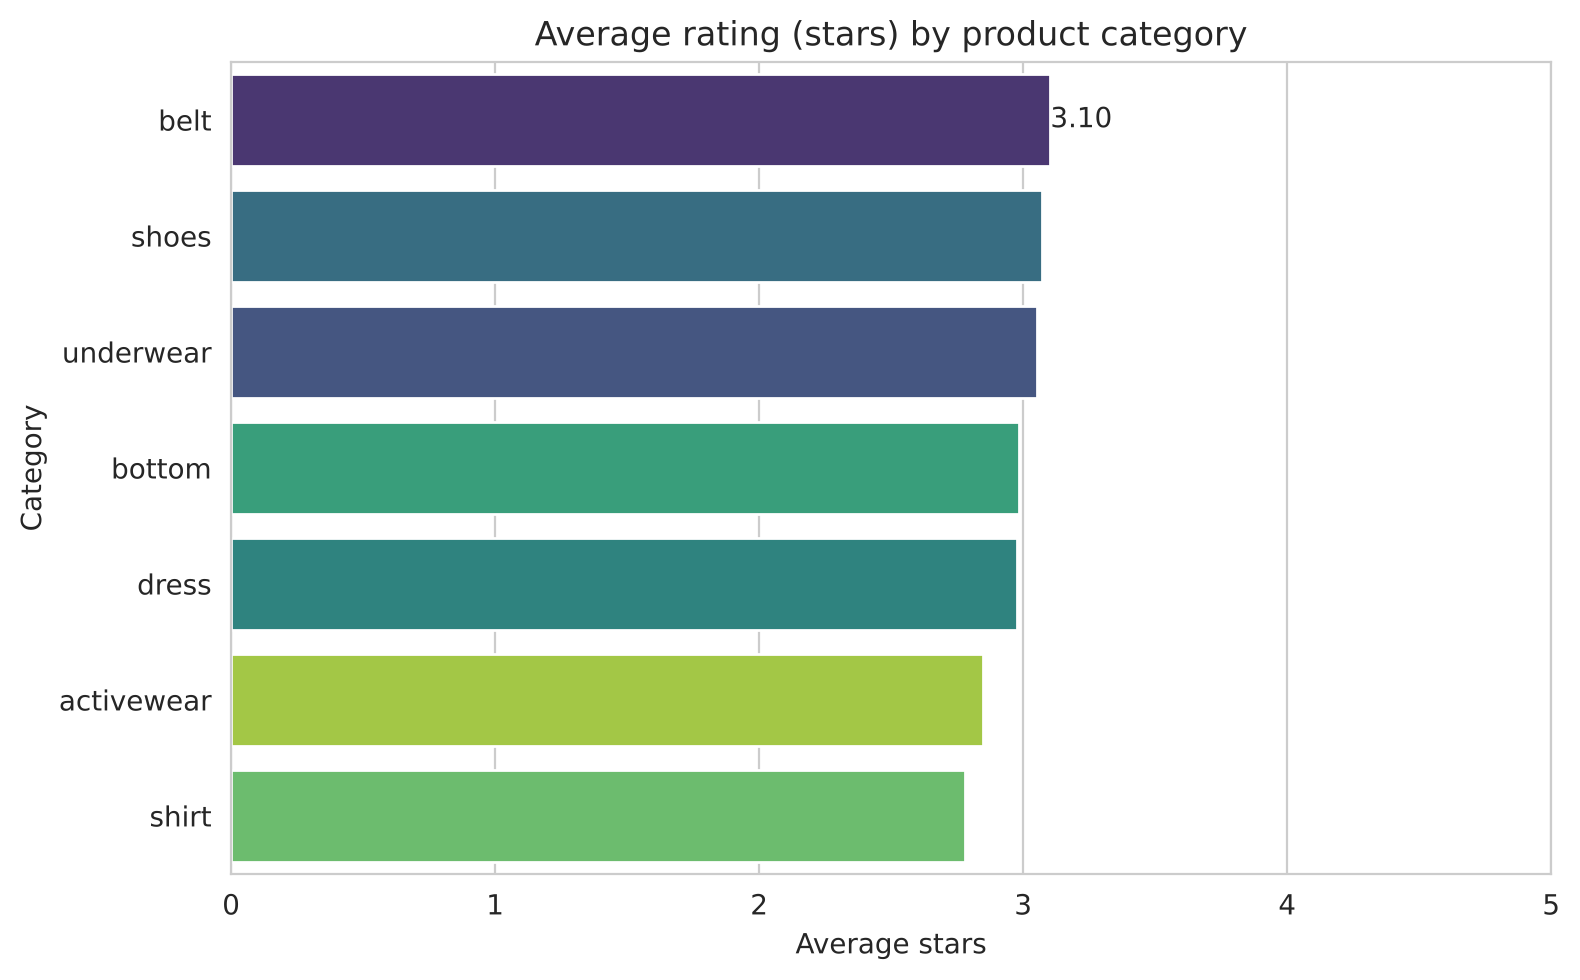

In [31]:
# Average rating per category, visualised
plt.figure(figsize=(8, 5))
order = category_stars.index
ax = sns.barplot(data=df, y='category', x='stars', order=order, hue='category', palette='viridis', legend=False, errorbar=None)
ax.bar_label(ax.containers[0], fmt='%.2f')
plt.title('Average rating (stars) by product category')
plt.xlabel('Average stars')
plt.ylabel('Category')
plt.xlim(0, 5)
plt.tight_layout()
plt.show()

In [32]:
# Average rating per price level
level_stars = df.groupby('level')['stars'].agg(['mean', 'count']).sort_values('mean', ascending=False)
level_stars['mean'] = level_stars['mean'].round(2)

level_stars

,mean,count
level,,
average,3.05,234
cheap,3.04,332
premium,2.97,433


`level_stars` checks whether price is related to satisfaction.

Here the highest ratings go to average and cheap products, which are practically tied.

In [33]:
# Sales and average rating per designer (sorted by number of sales)
designer_summary = df.groupby('designer_id')['stars'].agg(['count', 'mean']).rename(columns={'count': 'n_sales', 'mean': 'avg_stars'})
designer_summary['avg_stars'] = designer_summary['avg_stars'].round(2)
designer_summary = designer_summary.sort_values('n_sales', ascending=False)

designer_summary.head(10)

,n_sales,avg_stars
designer_id,,
110,54,3.19
102,53,3.02
117,52,2.90
105,51,2.78
113,48,2.92
106,46,2.91
101,46,3.02
103,46,2.91
112,46,2.83


The next chart, a scatter plot, shows number of sales vs average rating for each designer.
Designers in the top right (many sales and high ratings) would be the top performers, while those in the bottom right (many sales but low ratings) should be treated as a warning sign: they sell thanks to brand awareness or price, but risk disappointing buyers.

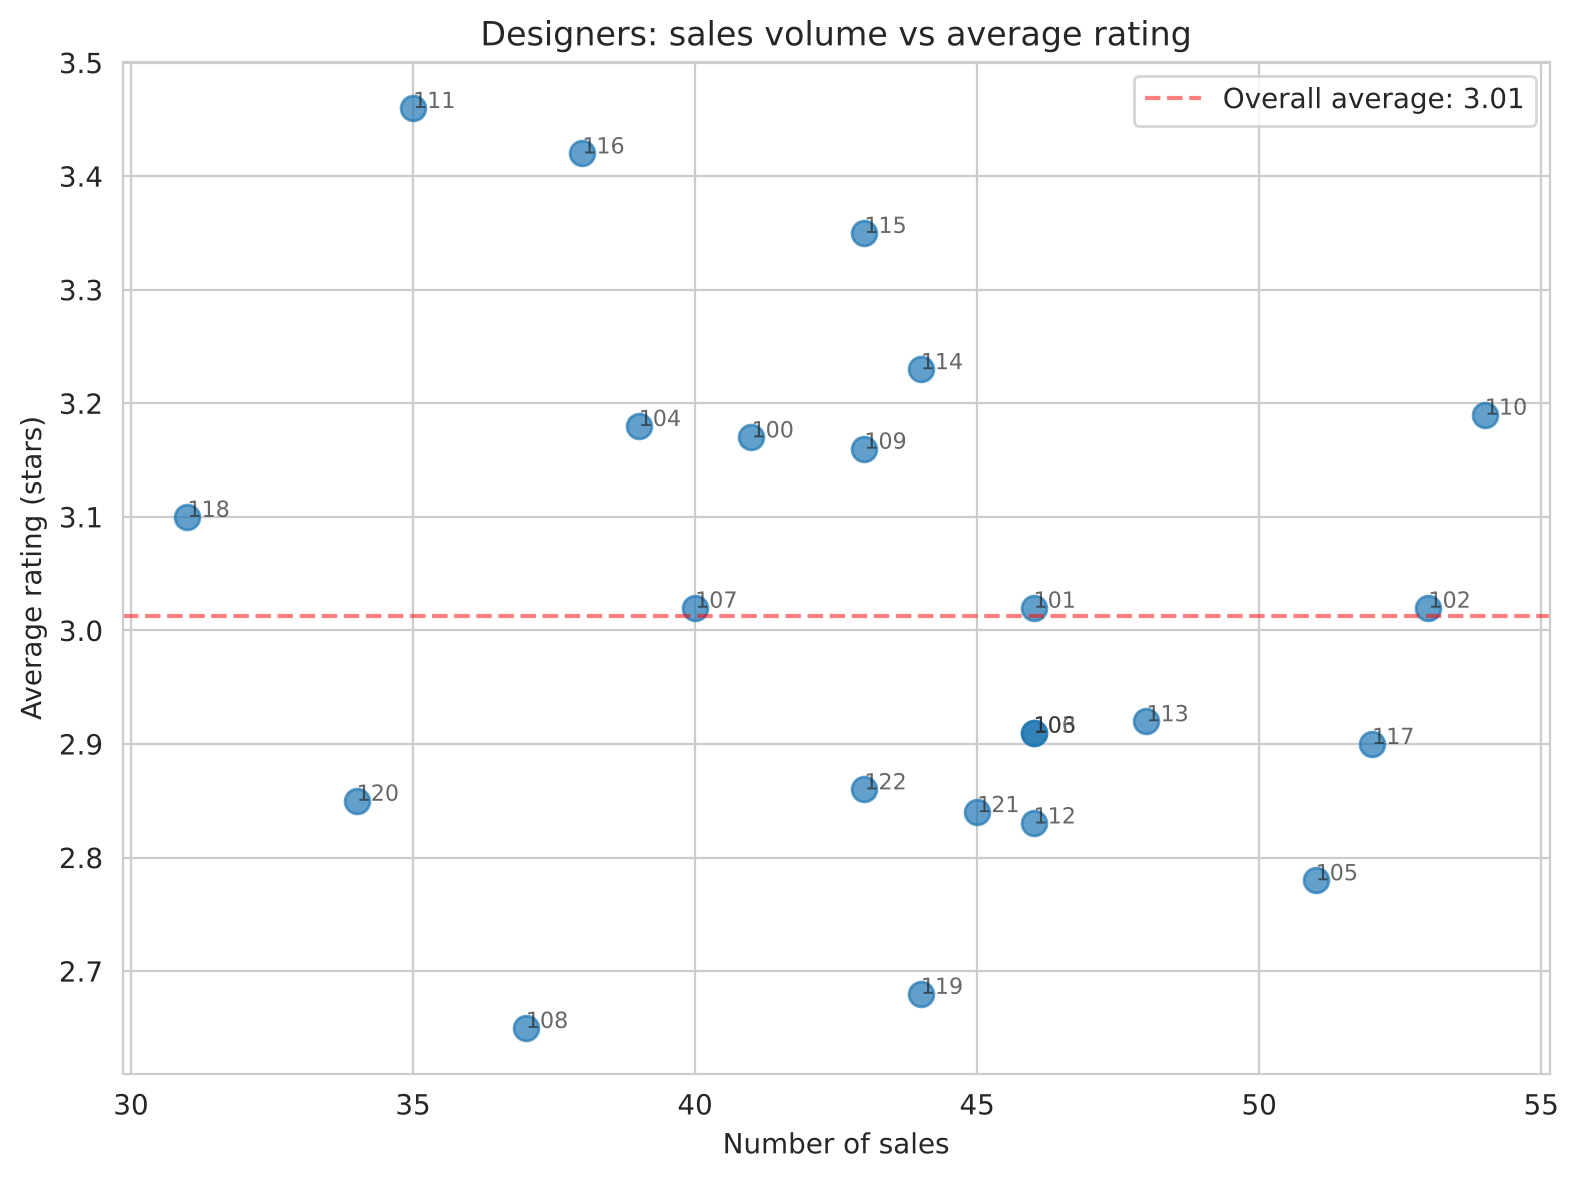

In [34]:
# Scatter: number of sales vs average rating, per designer
plt.figure(figsize=(8, 6))
plt.scatter(designer_summary['n_sales'], designer_summary['avg_stars'], s=80, alpha=0.7)
plt.axhline(df['stars'].mean(), color='red', linestyle='--', alpha=0.5, label=f"Overall average: {df['stars'].mean():.2f}")

for idx, row in designer_summary.iterrows():
    plt.annotate(str(idx), (row['n_sales'], row['avg_stars']), fontsize=8, alpha=0.7)

plt.title('Designers: sales volume vs average rating')
plt.xlabel('Number of sales')
plt.ylabel('Average rating (stars)')
plt.legend()
plt.tight_layout()
plt.show()

There are no top performers and no clear trend. The situation is examined further below.

In [35]:
# Correlation between sales volume and average rating, at designer level
correlation = designer_summary['n_sales'].corr(designer_summary['avg_stars'])
print(f"Correlation n_sales vs avg_stars: {correlation:.2f}")
print()
print("n_sales range:", designer_summary['n_sales'].min(), "-", designer_summary['n_sales'].max())
print("avg_stars range:", round(designer_summary['avg_stars'].min(), 2), "-", round(designer_summary['avg_stars'].max(), 2))

Correlation n_sales vs avg_stars: -0.24

n_sales range: 31 - 54
avg_stars range: 2.65 - 3.46


- The correlation is -0.24, i.e. weak and slightly negative: there is no strong relationship between how much a designer sells and how well they are rated, in line with what the scatter plot shows.
- The reason there are no "top performers" in the top right lies in the numbers: the number of sales per designer varies little (from 31 to 54, a narrow range, with the 23 designers mostly concentrated between 35 and 50), and average stars only range from 2.65 to 3.46, very close to the middle of the scale (3), with no designer really standing out upwards or downwards. This is consistent with what was already noted in the univariate analysis: the distribution of stars is almost uniform (about 20% for each value from 1 to 5), so when averaging over dozens of sales per designer, all averages naturally converge towards the central value (about 3), flattening any possible difference between designers.

**Note:** with this data, it is not possible to objectively identify "successful designers" based on stars alone.

The category × level heatmap shows whether certain categories are sold mostly in a specific price level.

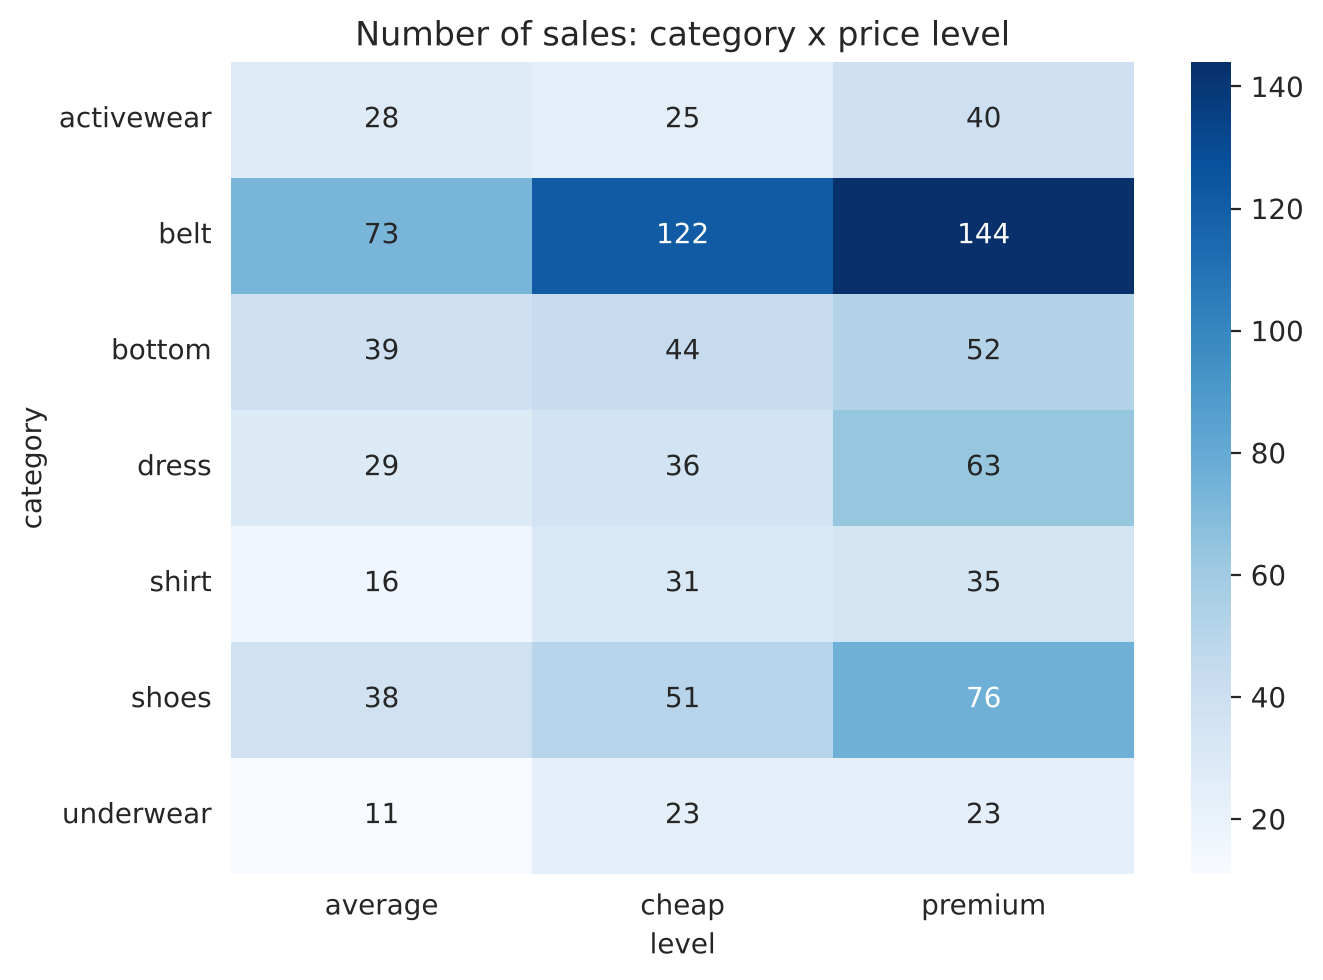

In [36]:
# Cross distribution: category x level (heatmap of counts)
cross_cat_level = pd.crosstab(df['category'], df['level'])

plt.figure(figsize=(7, 5))
sns.heatmap(cross_cat_level, annot=True, fmt='d', cmap='Blues')
plt.title('Number of sales: category x price level')
plt.tight_layout()
plt.show()

Belts stand out here, sold mostly in the premium level.

## User-level analysis
The focus now shifts from individual products/designers to the behaviour of selling users: how many sales each one makes, what value they generate, how long they have been registered.

This is the basis on which the personas will be built in Tableau.

Below is the central table of this section: one user per row, with how much they sell, their average rating and how long they have been registered. Every reasoning about user segments starts from here.

In [37]:
# User-level aggregation: number of sales, average rating, average tenure
user_summary = df.groupby('user_uuid').agg(
    n_sales=('item_id', 'count'),
    avg_stars=('stars', 'mean'),
    avg_tenure_days=('account_tenure_days', 'mean')
).round(2)

user_summary = user_summary.sort_values('n_sales', ascending=False)
user_summary.head(10)

,n_sales,avg_stars,avg_tenure_days
user_uuid,,,
182,11,2.73,839.82
131,10,2.20,453.40
190,10,2.80,622.70
119,10,3.20,306.70
225,9,2.67,682.78
233,9,2.67,469.33
181,9,3.00,758.11
197,9,3.22,512.00
155,8,2.62,177.12


The histogram below, of the number of sales, shows whether there are a few "power sellers" and many occasional users (a strongly skewed distribution), or whether sales are spread more evenly across users.

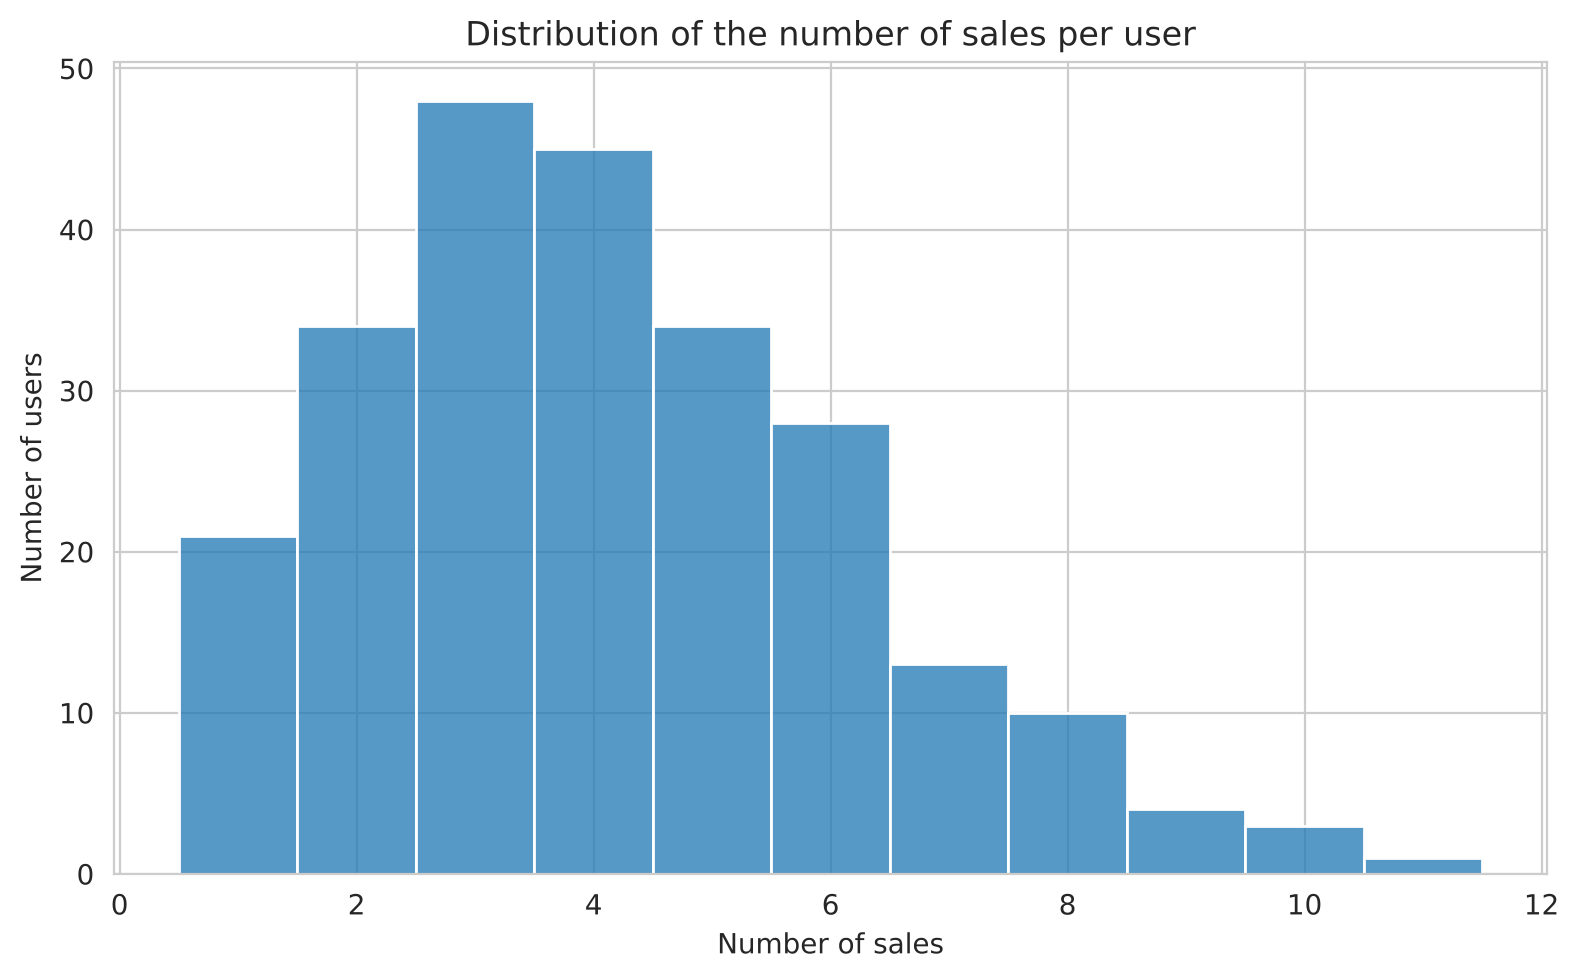

count    241.000000
mean       4.145228
std        2.089574
min        1.000000
25%        3.000000
50%        4.000000
75%        5.000000
max       11.000000
Name: n_sales, dtype: float64


In [38]:
# Distribution of the number of sales per user
plt.figure(figsize=(8, 5))
sns.histplot(user_summary['n_sales'], bins=range(1, user_summary['n_sales'].max() + 2), discrete=True)
plt.title('Distribution of the number of sales per user')
plt.xlabel('Number of sales')
plt.ylabel('Number of users')
plt.tight_layout()
plt.show()

print(user_summary['n_sales'].describe())

There are no extreme outliers, such as a user with 100 sales shifting the whole average. The distribution is reasonably even.
About 23% of users (55 out of 241) made only 1–2 sales over the whole period, while 18 users made 8 or more; so there is a moderate polarisation between occasional and more active users, but it is not extreme.

--------

The table below tries to distinguish user profiles.

In [39]:
# Prevailing price level sold by each user (to understand the user's "profile")
user_level_mix = pd.crosstab(df['user_uuid'], df['level'])
user_level_mix['prevailing_level'] = user_level_mix.idxmax(axis=1)

user_level_mix['prevailing_level'].value_counts()

prevailing_level
premium    94
cheap      76
average    71
Name: count, dtype: int64

Interestingly, premium is the prevailing level for the largest number of users, even though belts (typically an accessory, often associated with cheap items) were the best-selling category overall.
The prevailing level per user does not necessarily reflect the best-selling level overall. Next, the link between each user's prevailing level and their average rating is checked.

In [40]:
# Join the prevailing level to the user summary
user_summary = user_summary.join(user_level_mix['prevailing_level'])
user_summary.head(10)

,n_sales,avg_stars,avg_tenure_days,prevailing_level
user_uuid,,,,
182,11,2.73,839.82,premium
131,10,2.20,453.40,cheap
190,10,2.80,622.70,premium
119,10,3.20,306.70,premium
225,9,2.67,682.78,average
233,9,2.67,469.33,cheap
181,9,3.00,758.11,premium
197,9,3.22,512.00,average
155,8,2.62,177.12,cheap


In [41]:
# Link between prevailing level per user and average rating
user_summary.groupby('prevailing_level')['avg_stars'].mean().round(2)

prevailing_level
average    3.10
cheap      2.95
premium    3.05
Name: avg_stars, dtype: float64

In [42]:
# And the link with the number of sales (do premium users sell more or less?)
user_summary.groupby('prevailing_level')['n_sales'].mean().round(2)

prevailing_level
average    3.83
cheap      4.26
premium    4.29
Name: n_sales, dtype: float64

**Summary**
The number of sales per user is relatively contained (mean 4.1, median 4, range 1–11): there are no extreme "power sellers" dominating the marketplace. There is, however, a moderate polarisation: about 23% of users made only 1–2 sales in the observed period, while 18 users (7.5%) made 8 or more. In terms of price positioning, users whose prevailing level is premium are the largest group (94 out of 241, 39%), followed by cheap (76) and average (71).

---

The scatter plot below (sales × tenure, coloured by prevailing level) shows visually how these profiles are positioned. This is not yet actual clustering.

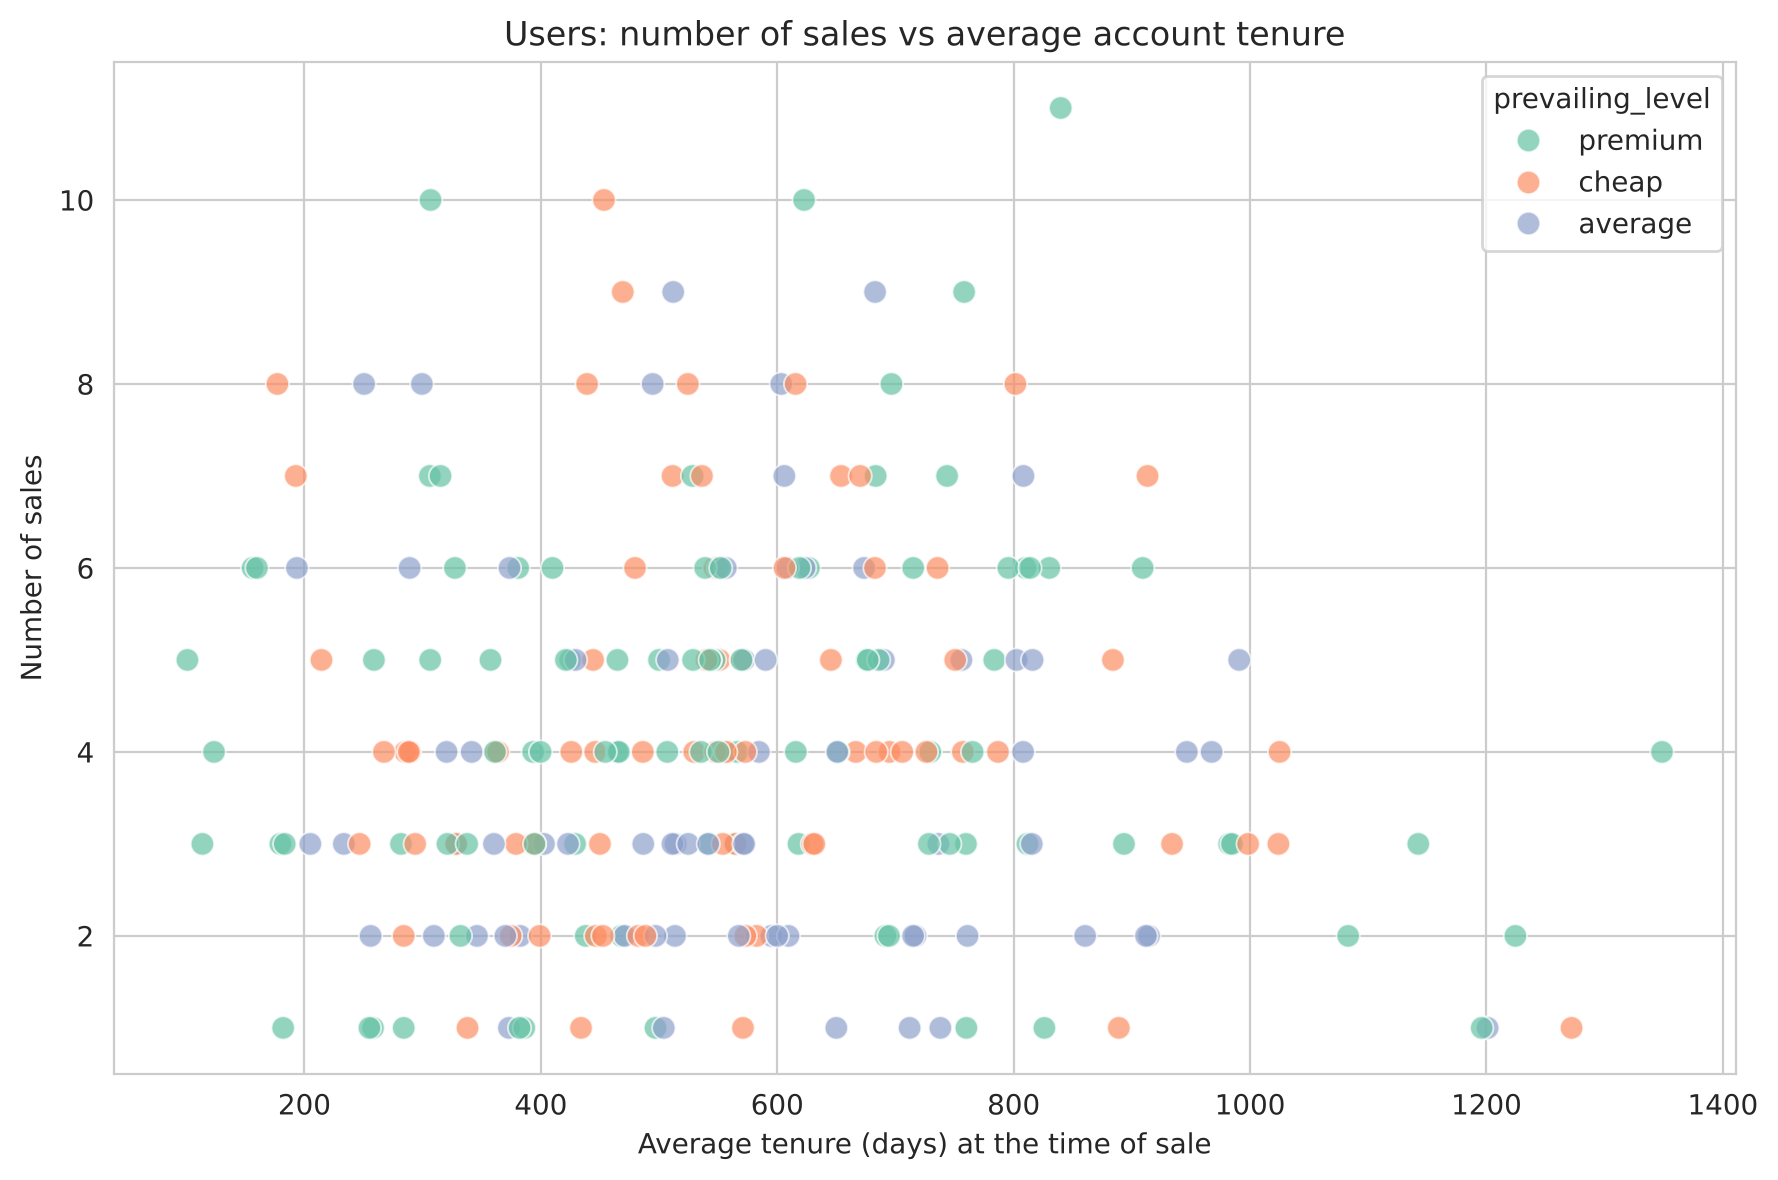

In [43]:
# Scatter: number of sales vs account tenure, coloured by prevailing level
plt.figure(figsize=(9, 6))
sns.scatterplot(data=user_summary, x='avg_tenure_days', y='n_sales', hue='prevailing_level', palette='Set2', alpha=0.7, s=70)
plt.title('Users: number of sales vs average account tenure')
plt.xlabel('Average tenure (days) at the time of sale')
plt.ylabel('Number of sales')
plt.tight_layout()
plt.show()

## Key insights and conclusions

The EDA closes with an overview of the numeric correlations and a structured summary of the insights gathered. This will serve as the basis for both the presentation and the Tableau dashboard.

The correlation heatmap checks whether account tenure (`account_tenure_days`) is related to the rating (`stars`), i.e. whether veteran users tend to sell better-rated products.

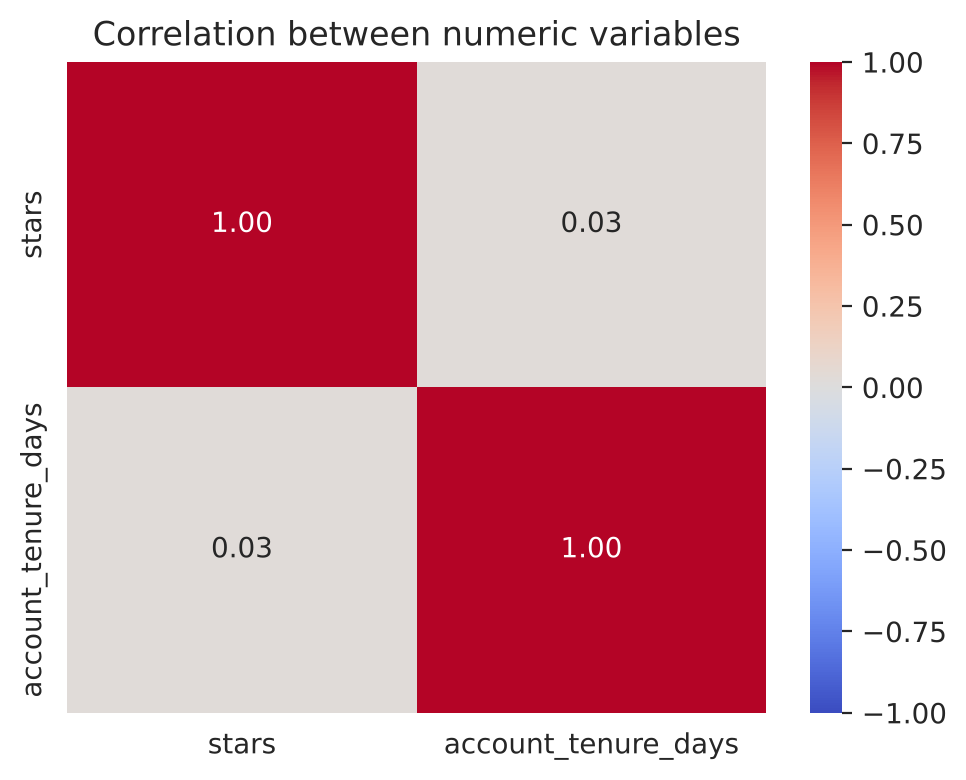

In [44]:
# Correlation matrix of the main numeric variables
numeric_cols = ['stars', 'account_tenure_days']
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(5, 4))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title('Correlation between numeric variables')
plt.tight_layout()
plt.show()

There is no apparent correlation: 0.03 is very close to zero.

---

Below is a summary table that gives an overview of the dataset.

In [45]:
# Summary of the main KPIs of the dataset
summary = pd.DataFrame({
    'metric': [
        'Total sales', 'Unique users', 'Unique designers', 'Categories',
        'Period covered', 'Average sales per user', 'Overall average stars',
        'Average account tenure at sale (days)'
    ],
    'value': [
        len(df), df['user_uuid'].nunique(), df['designer_id'].nunique(), df['category'].nunique(),
        f"{df['purchase_date'].min().date()} - {df['purchase_date'].max().date()}",
        round(len(df) / df['user_uuid'].nunique(), 2), round(df['stars'].mean(), 2),
        round(df['account_tenure_days'].mean(), 1)
    ]
})

summary

,metric,value
0,Total sales,999
1,Unique users,241
2,Unique designers,23
3,Categories,7
4,Period covered,2021-01-01 - 2023-12-28
5,Average sales per user,4.15
6,Overall average stars,3.01
7,Average account tenure at sale (days),558.0


### Conclusions
#### Data quality notes
- `item_id` has 98 duplicated values which, on inspection, correspond to different items (different category/designer): most likely a collision in ID generation, so it should not be used as a unique product key.
- `language` and `country` are perfectly redundant (1:1 mapping with no exceptions): in reality one would expect more variability (e.g. users selling in English without being native speakers).
- The distribution of `stars` is almost perfectly uniform (~20% for each value from 1 to 5): an unusual pattern for real reviews (usually positively skewed), which suggests random generation in this synthetic dataset. This limits the possibility of drawing reliable insights on perceived quality at designer or category level.

#### Main insights
- **Belt** is the best-selling category (34% of sales), a surprising result compared with what one would expect from a real fashion marketplace (where garments such as shirts/shoes usually dominate).
- Monthly sales volume grew markedly from 2021 to 2023, a sign of a marketplace in expansion.
- There is no relationship between sales volume and average rating at designer level (correlation ≈ -0.24): with the current data it is not possible to objectively identify "successful" designers based on stars.
- At user level there are no extreme power sellers (range 1–11 sales, mean 4.1), but there is a moderate polarisation: ~23% of users with 1–2 sales against ~7.5% with 8+.
- The prevailing price level per user is distributed fairly evenly between premium (39%), cheap (32%) and average (29%).

#### Limitations and notes for the next part (Tableau/ML)
- Given the synthetic nature of some variables (uniform stars, redundant language), personas and segmentation should be built mainly on `n_sales`, `level`/`prevailing_level` and `account_tenure_days`, which show more realistic variability, rather than on `stars`.
- `user_summary` is ready to be exported and used as the basis for clustering/personas in Tableau.

## Export
Finally, `user_summary` is exported: the user-level table built in the "User-level analysis" section. In the original dataset (`df`) each row is a single sale (one row = one transaction), which is useful for the EDA but is not the right shape for segmenting users, because the same user appears on several rows with different sales.

The `user_summary` dataset, instead, has one row per user with the metrics needed to tell them apart and group them into profiles:
- `n_sales` → how active/prolific the user is
- `avg_stars` → average perceived quality of their products
- `avg_tenure_days` → how long they have been on the platform
- `prevailing_level` → whether they mainly sell cheap, average or premium items

This combination makes it possible to distinguish the different user profiles.

**What the next cell does**
- `reset_index()` turns `user_uuid` from the dataframe index into a proper column. This matters because Tableau reads CSV files by column and does not recognise the pandas index, so without it the user ID could be lost on import.
- `to_csv(..., index=False)` stops pandas from writing an extra sequential numeric column (the dataframe index), which is not needed and would clutter the Tableau import.
- The file `user_summary_tableau.csv` will be saved in the same folder as the notebook.

In [46]:
# Export user_summary to CSV for import into Tableau
user_summary_export = user_summary.reset_index()  # bring user_uuid back as a column, not the index
user_summary_export.to_csv('user_summary_tableau.csv', index=False)

user_summary_export.head()

,user_uuid,n_sales,avg_stars,avg_tenure_days,prevailing_level
0,182,11,2.73,839.82,premium
1,131,10,2.20,453.40,cheap
2,190,10,2.80,622.70,premium
3,119,10,3.20,306.70,premium
4,225,9,2.67,682.78,average
